Copyright: Vrije Universiteit Amsterdam, Faculty of Humanities, CLTL

# Lab 5.1: Querying Word Vectors

In this lab we learn how to represent words using a pre-trained model. We will work with the English fasttext model [wiki-news-300d-1M.vec](https://fasttext.cc/docs/en/english-vectors.html). Download it and save it to the data folder. 

You can download models for other languages [here](https://fasttext.cc/docs/en/crawl-vectors.html) at the bottom of the page. 

We use the *gensim* module to query the model. The model is quite big, so the following loading step takes long: 

In [1]:
from gensim.models import KeyedVectors
print("loading")
word_vectors = KeyedVectors.load_word2vec_format("../data/wiki-news-300d-1M.vec")
print("done loading")

loading
done loading


We can now get the vector representation for a word from the model. Note that the model only contains one million words. Some words can thus not be found and you will get a *KeyError*.  

In [2]:
term ="veganism"
term_vector = word_vectors.get_vector(term)

print(term_vector)

[ 3.740e-02  4.961e-01  1.124e-01  2.100e-02  4.520e-02  3.590e-02
  1.480e-02 -1.180e-02  8.290e-02  1.670e-01  1.262e-01 -1.175e-01
  5.210e-02  1.447e-01 -2.944e-01 -8.590e-02 -2.107e-01  1.318e-01
  2.050e-02  6.470e-02 -5.668e-01  5.710e-02 -8.020e-02  2.397e-01
 -1.151e-01 -8.840e-02 -3.179e-01 -1.309e-01  1.753e-01  1.340e-01
 -3.487e-01 -1.303e-01 -1.522e-01 -4.930e-02 -2.050e-02 -2.003e-01
 -1.092e-01  2.151e-01  3.580e-02  5.642e-01 -4.780e-02 -6.530e-02
 -7.140e-02 -1.741e-01 -2.485e-01  8.130e-02 -4.400e-03  2.259e-01
 -3.270e-02  1.249e-01  6.400e-02 -5.810e-02 -8.261e-01  8.770e-02
 -1.842e-01 -3.190e-02  3.040e-02 -1.162e-01  4.000e-02 -2.710e-02
 -3.740e-02 -1.339e-01 -8.600e-02  2.310e-02  1.182e-01 -1.411e-01
 -3.800e-03  1.276e-01 -4.325e-01  4.060e-02 -1.289e-01 -6.420e-02
  3.950e-02 -1.409e-01 -2.768e-01  1.637e-01  1.449e-01 -8.090e-02
 -2.640e-02  1.907e-01  8.100e-03  5.280e-02 -1.748e-01 -1.687e-01
 -4.800e-02 -4.970e-02 -1.470e-02  5.650e-02  2.039e-01 -2.515

## 1. Calculating similarity
Gensim provides different options to calculate the similarity between words. The standard measure for determining the similarity between words is to calculate the cosine similarity between their vectors. 

In [3]:
term1 ="vegetables"
term2 = "fruit"

word_vectors.similarity(term1,term2)

0.7075582

In [4]:
word_vectors.most_similar(term)

[('vegetarianism', 0.8172020316123962),
 ('Veganism', 0.8091330528259277),
 ('vegan', 0.7639820575714111),
 ('vegans', 0.7636191248893738),
 ('non-vegans', 0.6928225159645081),
 ('vegetarian', 0.6850114464759827),
 ('non-vegan', 0.6824153065681458),
 ('fruitarianism', 0.6795083284378052),
 ('vegetarians', 0.6785328984260559),
 ('carnist', 0.6718637347221375)]

## 2. Arithmetic operations

Word vectors have become famous because they make it possible to perform arithmetic operations over word vectors. The most popular example is: 
woman + king - man = queen

In [5]:
word_vectors.most_similar(positive=["woman", "king"], negative=["man"])

[('queen', 0.751591145992279),
 ('monarch', 0.6741327047348022),
 ('princess', 0.6713886857032776),
 ('kings', 0.669899046421051),
 ('kingdom', 0.5971319079399109),
 ('royal', 0.592106282711029),
 ('uncrowned', 0.5911506414413452),
 ('prince', 0.5909028053283691),
 ('lady', 0.5904011130332947),
 ('monarchs', 0.5884358286857605)]

In [6]:
term ="veganism"
subtract ="vegetarian"
word_vectors.most_similar(positive=[term], negative=[subtract])

[('antifeminism', 0.2874734103679657),
 ('Veganism', 0.2864731550216675),
 ('GamerGate', 0.28277936577796936),
 ('anti-feminism', 0.2799191176891327),
 ('Sicko', 0.2706912159919739),
 ('gamergate', 0.26813608407974243),
 ('masculism', 0.2663191854953766),
 ('Gamergate', 0.266033411026001),
 ('TFYC', 0.26466166973114014),
 ('ZHCs', 0.2637418210506439)]

## 3. Training your own model

The word vectors have been trained on Wikipedia. You can also train word vectors on your own dataset. **In this example, we only apply tokenization and lowercasing. Discuss which pre-processing steps you want to use for your dataset.**

In [7]:
import pandas as pd
import stanza

# Read in TSV
tsv_file = "../data/veganism_overview_en.tsv"
content = pd.read_csv(tsv_file, sep="\t", header = 0, keep_default_na=False)
articles = content["Text"]
stanza.download("en")
tokenizer = stanza.Pipeline('en', processors='tokenize')
tokenized = []
for article in articles:
    for sent in tokenizer(article).sentences:
        tokenized.append([tok.text.lower() for tok in sent.tokens])
print(tokenized)

2024-12-13 12:29:02 INFO: Downloaded file to C:\Users\NIKHIL\stanza_resources\resources.json
2024-12-13 12:29:02 INFO: Downloading default packages for language: en (English) ...
2024-12-13 12:29:04 INFO: File exists: C:\Users\NIKHIL\stanza_resources\en\default.zip
2024-12-13 12:29:08 INFO: Finished downloading models and saved to C:\Users\NIKHIL\stanza_resources
2024-12-13 12:29:08 INFO: Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES


2024-12-13 12:29:08 INFO: Downloaded file to C:\Users\NIKHIL\stanza_resources\resources.json
2024-12-13 12:29:08 WARNING: Language en package default expects mwt, which has been added
2024-12-13 12:29:08 INFO: Loading these models for language: en (English):
| Processor | Package  |
------------------------
| tokenize  | combined |
| mwt       | combined |

2024-12-13 12:29:08 INFO: Using device: cpu
2024-12-13 12:29:08 INFO: Loading: tokenize
E:\Software\Anaconda\envs\LaD\lib\site-packages\stanza\models\tokenization\trainer.py:82: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that 

[['thirty', 'years', 'ago', ',', 'a', 'few', 'indian', '-', 'americans', 'got', 'together', 'to', 'form', 'vegetarian', 'vision', 'when', 'they', 'saw', 'more', 'and', 'more', 'indian', 'immigrants', 'becoming', 'non-vegetarian', 'of', 'the', 'difficulty', 'accessing', 'their', 'traditional', 'indian', 'products', '.'], ['“', 'people', 'coming', 'from', 'india', 'couldn’t', 'find', 'enough', 'vegetarian', 'food', '.'], ['so', 'they', 'were', 'changing', 'their', 'lifestyle', '.'], ['we', 'felt', 'an', 'organization', 'like', 'this', 'was', 'needed', ',', '”', 'chairman', 'h.k.'], ['shah', ',', 'founder', 'of', 'vegetarian', 'vision', 'founded', 'in', '1992', ',', 'now', 'called', 'world', 'vegan', 'vision', ',', 'told', 'news', 'india', 'times', '.'], ['he', 'and', 'his', 'wife', 'turned', 'vegan', '15', 'years', 'ago', '.'], ['for', 'an', 'indian', 'vegetarian', ',', 'to', 'turn', 'to', 'a', 'vegan', 'diet', 'bereft', 'of', 'dairy', 'products', ',', 'is', 'only', 'to', 'be', 'imagined

In [8]:
from gensim.models import Word2Vec
# Train a Word2Vec model, the min_count parameter indicates the minimum frequency of each word in the corpus
mymodel = Word2Vec(tokenized, min_count=2)

# summarize the loaded model
print(mymodel)


# Let's have a look at the 50 most frequent words
for index in range(50):
    print(mymodel.wv.index_to_key[index])


Word2Vec<vocab=2570, vector_size=100, alpha=0.025>
,
.
the
and
to
a
of
in
is
-
vegan
that
for
as
it
with
are
she
on
"
“
i
”
her
be
from
diet
but
this
based
you
not
have
by
was
or
more
veganism
plant
(
)
food
their
has
can
meat
at
he
all
animal


In [9]:
mymodel.wv.most_similar("plant")

[('-', 0.9995578527450562),
 ('diet', 0.9995267987251282),
 ('out', 0.9993648529052734),
 ('an', 0.9993395805358887),
 ('of', 0.9993253350257874),
 ('on', 0.9993228316307068),
 ('are', 0.999302089214325),
 ('foods', 0.999289333820343),
 ('the', 0.9992866516113281),
 ('in', 0.9992859959602356)]

You can see that function words are very dominant in this model because the dataset is so small. Training own word vectors is only reasonable with much larger datasets. **Discuss what would be a good training corpus for your analysis goals.**

## 4. Visualizing word vectors

Word vectors with 100 dimensions are difficult to conceptualize for human brains. As a simplification, it is common to apply a dimensionality reduction technique on the word vector to obtain a two-dimensional representation. Obviously, this two-dimensional vector contains much less information than the 100-dimensional vector. However, it can yield nice visualizations to provide anecdotal evidence.  

Popular algorithm for calculating the reduced dimensions are principal component analysis (PCA) and [T-SNE](https://lvdmaaten.github.io/tsne/). 

**Play around with different models, reduction techniques and term selection. Note that the dimensionality reduction for the big fasttext model takes very long and you might run into memory errors. It could help to run the code in a regular python file (.py) instead of in a jupyter notebook.** [This article](https://towardsdatascience.com/why-you-are-using-t-sne-wrong-502412aab0c0) provides some good advice on interpreting T-SNE output. 



In [10]:
from sklearn.decomposition import PCA 
from sklearn.manifold import TSNE
import numpy as np
# Select model 
model=word_vectors

# If you use a large model, you need to restrict the vocabulary to the most frequent terms
# If you use the full vocab it might cause a crash of the notebook
# Restricted
vocab = [model.index_to_key[i] for i in range(8000)]

# Apply dimensionality reduction with PCA or T-SNE
high_dimensional = np.asarray([model[w] for w in vocab])
reduction_technique = TSNE(n_components=2)
#reduction_technique = PCA(n_components=2)

print("Calculate dimensionality reduction")
two_dimensional = reduction_technique.fit_transform(high_dimensional)
print("Done")

Calculate dimensionality reduction
Done


In [11]:
# Get the indices in the vocabulary for selected terms
terms =["fruit", "meat", "salt","eat", "healthy", "good", "sugar", "sweet"]
term_indices = [model.key_to_index[t] for t in terms]

print(term_indices)

[3695, 3129, 4498, 3197, 3069, 173, 4089, 5041]


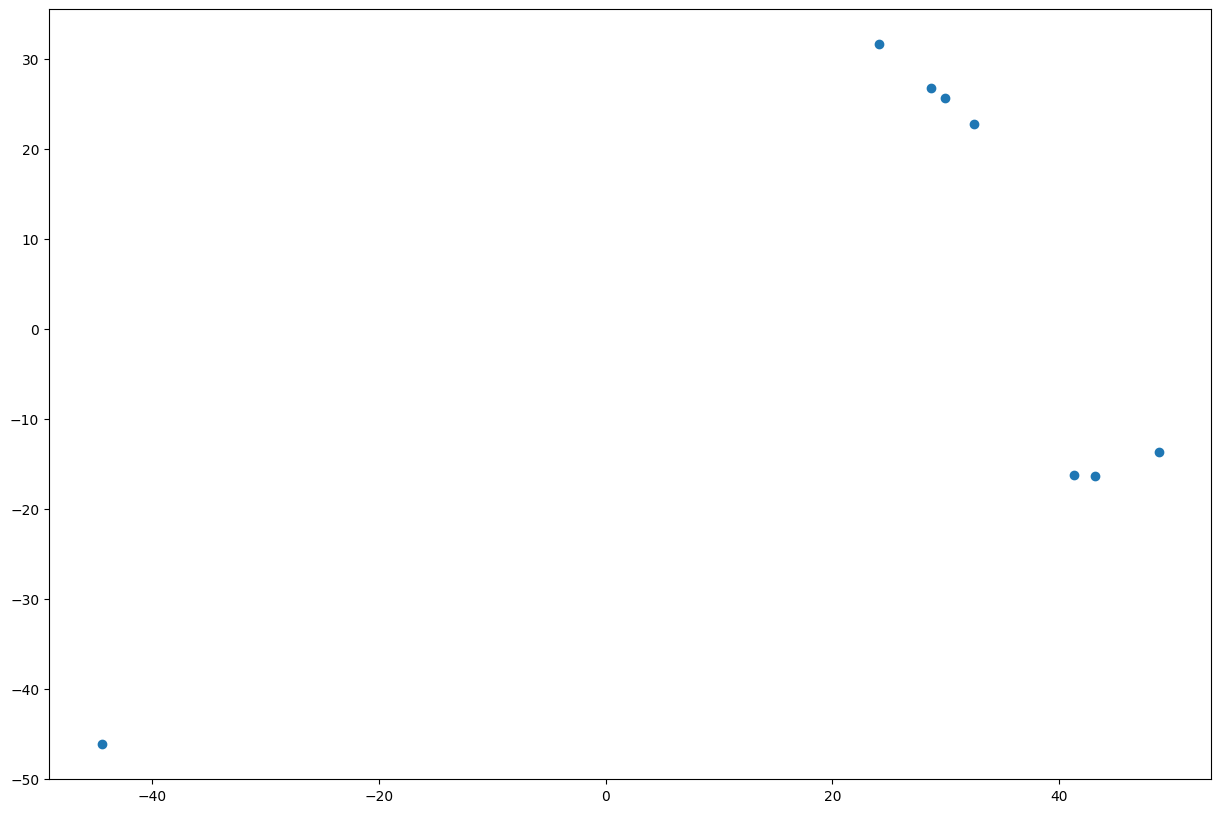

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize = (15, 10))

# Plot the two-dimensional vectors for the selected terms
x_values = [two_dimensional[index, 0] for index in term_indices]
y_values = [two_dimensional[index, 1] for index in term_indices]

ax.plot(x_values, y_values, 'o')


Let's improve the plot a bit. **Play around with the plotting options.**

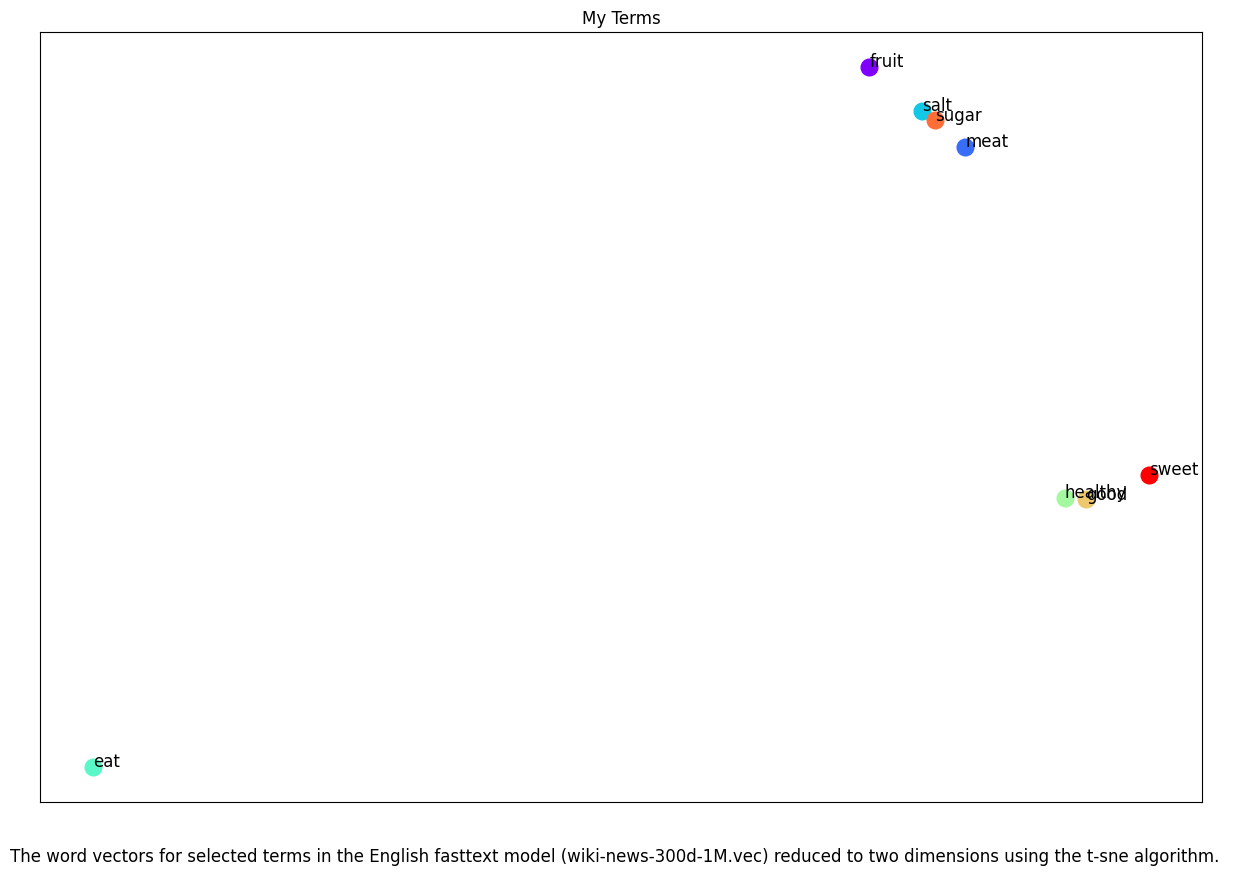

In [13]:
import matplotlib.cm as cm
import numpy as np 
fig, ax = plt.subplots(1, 1, figsize = (15, 10))

colors = cm.rainbow(np.linspace(0, 1, len(terms)))
for x, y, c in zip(x_values, y_values, colors):
    ax.plot(x, y, 'o', markersize=12, color=c)

# Add title and description
ax.set_title('My Terms')
description="The word vectors for selected terms in the English fasttext model (wiki-news-300d-1M.vec) reduced to two dimensions using the t-sne algorithm. "
fig.text(.51, .05, description, ha="center", fontsize=12)

# Hide the ticks 
ax.set_yticks([]) 
ax.set_xticks([])

# Annotate the terms in the plot
for i, word in enumerate(terms):
	plt.annotate(word, xy=(x_values[i], y_values[i]), fontsize = 12)
    
plt.show()

